# 03 - Modeling: Predicting Term Deposit Subscription
Trains Logistic Regression, Random Forest, and Gradient Boosting on two
feature sets (`realistic` vs `benchmark`, see `src/modeling.py`) and
compares them on ROC-AUC, PR-AUC, and recall on the positive class - the
metric that matters when the business cost of a missed subscriber is much
higher than the cost of an extra call.

In [1]:
import sys
sys.path.append('..')
import json
import pandas as pd
from IPython.display import Image, display

from src.modeling import run as run_modeling

results = run_modeling()
pd.DataFrame(results).drop(index=[], errors='ignore')

realistic__logistic_regression: ROC-AUC=0.8003  PR-AUC=0.4442  Recall(+)=0.651


realistic__random_forest: ROC-AUC=0.8126  PR-AUC=0.4768  Recall(+)=0.625


realistic__gradient_boosting: ROC-AUC=0.8088  PR-AUC=0.4812  Recall(+)=0.230


/Users/deep/Claude/marketing-analytics/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/deep/Claude/marketing-analytics/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/deep/Claude/marketing-analytics/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/deep/Claude/marketing-analytics/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/deep/Claude/marketing-analytics/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: over

benchmark__logistic_regression: ROC-AUC=0.9404  PR-AUC=0.5936  Recall(+)=0.904


benchmark__random_forest: ROC-AUC=0.9441  PR-AUC=0.6395  Recall(+)=0.915


benchmark__gradient_boosting: ROC-AUC=0.9493  PR-AUC=0.6592  Recall(+)=0.545


,realistic__logistic_regression,realistic__random_forest,realistic__gradient_boosting,benchmark__logistic_regression,benchmark__random_forest,benchmark__gradient_boosting,best_realistic_model
roc_auc,0.800301,0.812611,0.808841,0.940440,0.944070,0.949272,random_forest
pr_auc,0.444177,0.476838,0.481178,0.593641,0.639542,0.659197,random_forest
precision_positive,0.359524,0.423049,0.655385,0.449625,0.456206,0.652062,random_forest
recall_positive,0.650862,0.625000,0.229526,0.904095,0.914871,0.545259,random_forest
f1_positive,0.463190,0.504567,0.339984,0.600573,0.608820,0.593897,random_forest
accuracy,0.830015,0.861705,0.899587,0.864497,0.867533,0.915979,random_forest


In [2]:
metrics_df = pd.DataFrame({k: v for k, v in results.items() if isinstance(v, dict)}).T
metrics_df.sort_values('roc_auc', ascending=False)

,roc_auc,pr_auc,precision_positive,recall_positive,f1_positive,accuracy
benchmark__gradient_boosting,0.949272,0.659197,0.652062,0.545259,0.593897,0.915979
benchmark__random_forest,0.944070,0.639542,0.456206,0.914871,0.608820,0.867533
benchmark__logistic_regression,0.940440,0.593641,0.449625,0.904095,0.600573,0.864497
realistic__random_forest,0.812611,0.476838,0.423049,0.625000,0.504567,0.861705
realistic__gradient_boosting,0.808841,0.481178,0.655385,0.229526,0.339984,0.899587
realistic__logistic_regression,0.800301,0.444177,0.359524,0.650862,0.463190,0.830015


## Reading the comparison
- The **benchmark** feature set (includes `duration`) reproduces the
  ~0.94-0.95 ROC-AUC reported in Moro et al. (2014) - useful as a sanity
  check that the pipeline is correct, but not deployable (duration is only
  known *after* the call).
- The **realistic** feature set (~0.80-0.81 ROC-AUC) is what a marketing
  team could actually use to prioritize *before* dialing - this is the
  model saved to `models/best_model_realistic.joblib` and the one whose
  scores back the Power BI "predicted propensity" fields.

## Best realistic model: ROC curve, confusion matrix, feature importance

Best realistic-feature-set model: random_forest


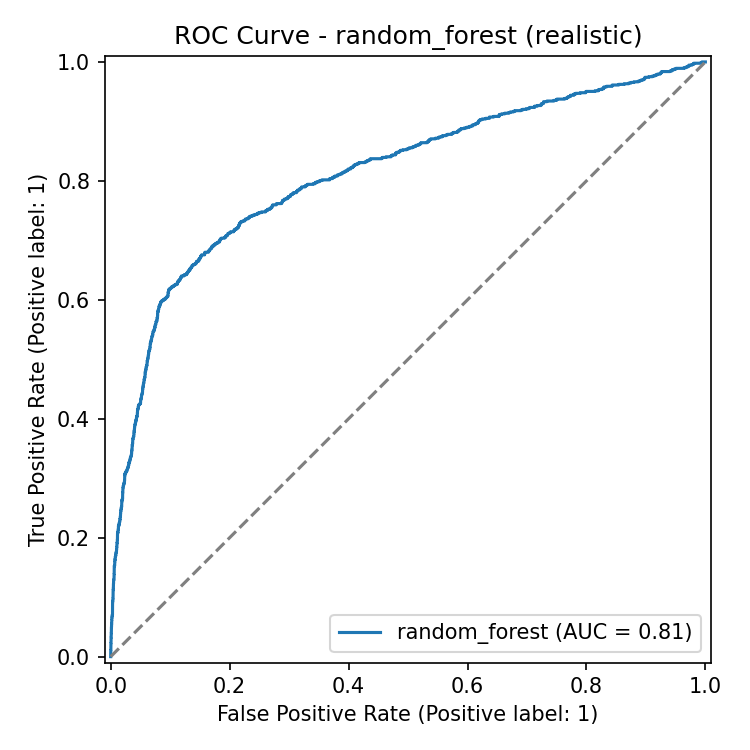

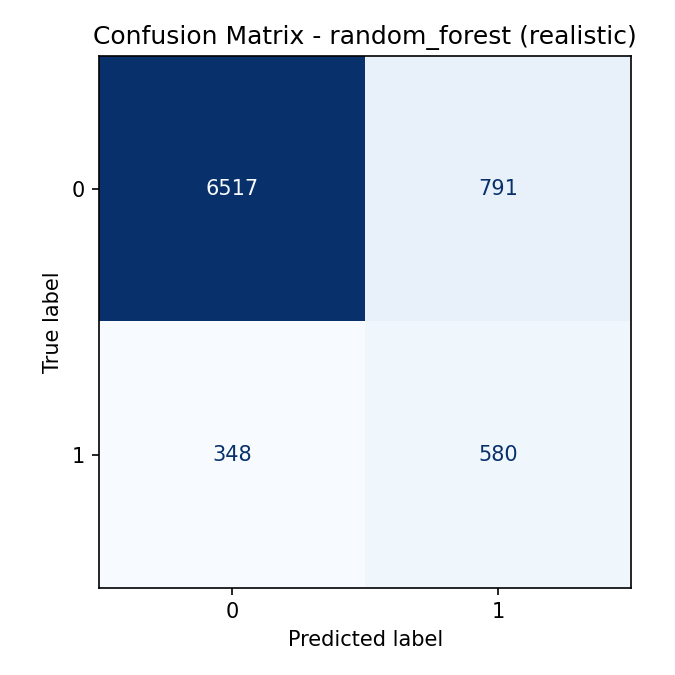

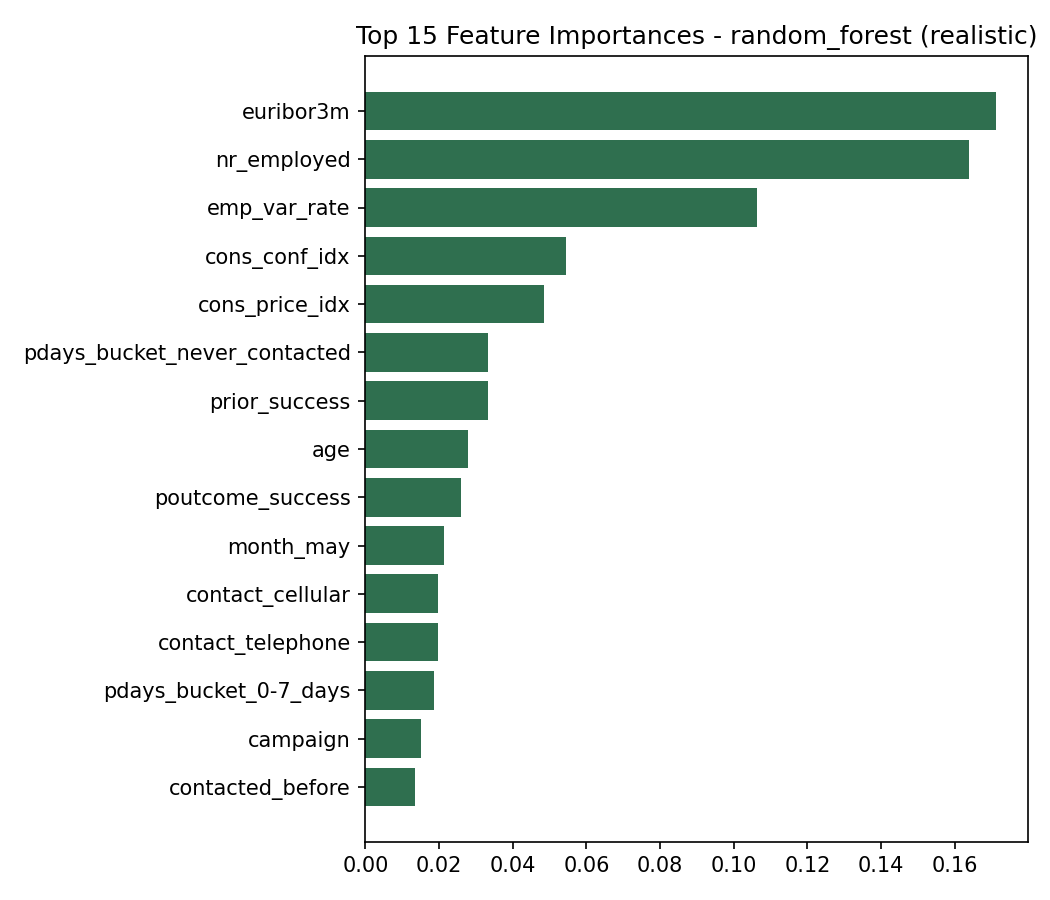

In [3]:
best_name = results['best_realistic_model']
print('Best realistic-feature-set model:', best_name)
display(Image(filename=f'../reports/figures/roc_realistic_{best_name}.png'))
display(Image(filename=f'../reports/figures/confusion_realistic_{best_name}.png'))
display(Image(filename=f'../reports/figures/feature_importance_realistic_{best_name}.png'))

## Key takeaways
- Prior campaign outcome, macro-economic context (`euribor3m`,
  `emp_var_rate`, `nr_employed`), and contact month dominate feature
  importance - reinforcing the EDA finding that *when* and *who you've
  already reached* matter more than static demographics.
- Recall on the positive class (not accuracy) is the metric to optimize
  given the ~11% base rate and the asymmetric cost of a missed subscriber
  vs. a wasted call.
- The saved model (`models/best_model_realistic.joblib`) can score new,
  uncalled leads to produce a propensity rank for the marketing team -
  the same scores feed the "Predicted Propensity" table exported for
  Power BI in `powerbi/`.